# PJM DART Spread — DOM Zone

EDA and results notebook.

In [1]:
import sys
from pathlib import Path
%load_ext autoreload
%autoreload 2

sys.path.append(str(Path.cwd().parent))

import pandas as pd

from scripts.data.data_collection import TEST_DATA_PATH, TRAIN_DATA_PATH, INPUT_DATA_DIR

train = pd.read_csv(TRAIN_DATA_PATH, index_col="interval_start_utc", parse_dates=True)
test = pd.read_csv(TEST_DATA_PATH, index_col="interval_start_utc", parse_dates=True)
df = pd.concat([train, test]).sort_index()
df.head()

,da_lmp,rt_lmp,da_energy,rt_energy,da_congestion,rt_congestion,da_loss,rt_loss,dart
interval_start_utc,,,,,,,,,
2019-01-01 00:00:00+00:00,24.550394,19.863592,24.27,19.66,0.000000,-0.083244,0.280394,0.288503,4.686802
2019-01-01 01:00:00+00:00,23.514936,19.357343,23.14,19.10,0.080000,0.002759,0.294936,0.259584,4.157593
2019-01-01 02:00:00+00:00,22.592422,18.809284,22.27,18.63,0.060069,0.000357,0.262353,0.180593,3.783138
2019-01-01 03:00:00+00:00,20.814471,18.482355,20.55,18.33,0.050000,0.000793,0.214471,0.149063,2.332116
2019-01-01 04:00:00+00:00,19.800852,18.052672,19.57,17.96,0.044227,0.000000,0.186625,0.093505,1.748180


## Shape, dtypes, coverage, missingness

In [2]:
print(f"rows: {len(df):,}   cols: {df.shape[1]}")
print(f"date range: {df.index.min()}  ->  {df.index.max()}")
print()
df.info()
print()
print("missing values per column:")
print(df.isna().sum())

rows: 66,456   cols: 9
date range: 2019-01-01 00:00:00+00:00  ->  2026-07-31 23:00:00+00:00

<class 'pandas.DataFrame'>
DatetimeIndex: 66456 entries, 2019-01-01 00:00:00+00:00 to 2026-07-31 23:00:00+00:00
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   da_lmp         66456 non-null  float64
 1   rt_lmp         66456 non-null  float64
 2   da_energy      66456 non-null  float64
 3   rt_energy      66456 non-null  float64
 4   da_congestion  66456 non-null  float64
 5   rt_congestion  66456 non-null  float64
 6   da_loss        66456 non-null  float64
 7   rt_loss        66456 non-null  float64
 8   dart           66456 non-null  float64
dtypes: float64(9)
memory usage: 5.1 MB

missing values per column:
da_lmp           0
rt_lmp           0
da_energy        0
rt_energy        0
da_congestion    0
rt_congestion    0
da_loss          0
rt_loss          0
dart             0
dtype: int64


## Gaps in the hourly index

The index should be one row per hour with no duplicates. Check both, since gaps or dupes (e.g. around DST transitions) would silently bias any time-based feature or backtest.

In [3]:
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
missing_hours = full_range.difference(df.index)
dupe_hours = df.index[df.index.duplicated()]

print(f"expected hourly rows: {len(full_range):,}")
print(f"missing hours: {len(missing_hours)}")
print(f"duplicate index timestamps: {len(dupe_hours)}")
if len(missing_hours):
    print(missing_hours[:10])
if len(dupe_hours):
    print(dupe_hours[:10])

expected hourly rows: 66,456
missing hours: 0
duplicate index timestamps: 0


## Descriptive statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
da_lmp,66456.0,47.629167,55.686515,6.640822,23.772625,33.498426,52.441556,1877.355112
rt_lmp,66456.0,49.044841,85.365464,-53.570167,21.584817,30.272801,49.349619,4392.119704
da_energy,66456.0,39.874326,38.707251,6.190000,22.170000,30.240000,45.100000,1501.140000
rt_energy,66456.0,40.184551,59.854383,-52.770000,20.510000,28.260000,44.090000,3700.000000
da_congestion,66456.0,6.926609,21.046889,-22.579648,0.607489,2.102780,5.648133,686.424415
rt_congestion,66456.0,8.073004,35.379727,-198.758623,0.000000,0.764630,3.925267,940.522654
da_loss,66456.0,0.828232,1.401758,-6.812422,0.158091,0.523445,1.123331,54.798858
rt_loss,66456.0,0.787705,2.381624,-10.362411,0.163857,0.457619,0.942364,275.580569
dart,66456.0,-1.415674,65.579747,-3977.226617,-1.217778,2.264480,7.465169,1075.259888


## Distribution of DART

`dart = da_lmp - rt_lmp`. Positive favors INC offers, negative favors DEC bids. Energy price spreads are typically heavy-tailed (RT prices spike during scarcity events), so check skew/kurtosis and look at the tails directly rather than assuming near-normality.

mean:     -1.416
median:   2.264
std:      65.580
skew:     -20.770
kurtosis: 902.105
share > 0 (INC favorable): 67.9%
share < 0 (DEC favorable): 32.1%


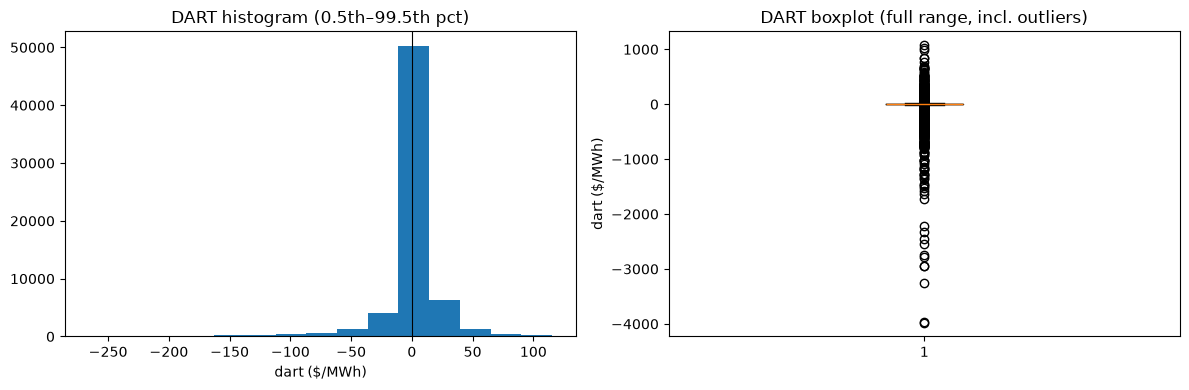

In [5]:
import matplotlib.pyplot as plt

print(f"mean:     {df['dart'].mean():.3f}")
print(f"median:   {df['dart'].median():.3f}")
print(f"std:      {df['dart'].std():.3f}")
print(f"skew:     {df['dart'].skew():.3f}")
print(f"kurtosis: {df['dart'].kurtosis():.3f}")
print(f"share > 0 (INC favorable): {(df['dart'] > 0).mean():.1%}")
print(f"share < 0 (DEC favorable): {(df['dart'] < 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["dart"], bins=200)
axes[0].set_xlim(df["dart"].quantile(0.005), df["dart"].quantile(0.995))
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("DART histogram (0.5th–99.5th pct)")
axes[0].set_xlabel("dart ($/MWh)")

axes[1].boxplot(df["dart"], showfliers=True)
axes[1].set_title("DART boxplot (full range, incl. outliers)")
axes[1].set_ylabel("dart ($/MWh)")

plt.tight_layout()
plt.show()

### Most extreme DART hours

The largest spreads are where virtual trading PnL — and forecast error — would concentrate. The most negative values below cluster on Dec 23–24, 2022: PJM's emergency load-shed event during Winter Storm Elliott, when RT prices spiked to their system cap while DA prices (set the day before) had no way to see it coming — a textbook example of why DART has fat tails and why any leak-free feature set will still miss ex-ante-unforecastable events like this one.

In [6]:
cols = ["da_lmp", "rt_lmp", "dart"]
print("largest positive DART (INC-favorable):")
display(df.nlargest(5, "dart")[cols])

print("\nlargest negative DART (DEC-favorable):")
display(df.nsmallest(5, "dart")[cols])

largest positive DART (INC-favorable):


,da_lmp,rt_lmp,dart
interval_start_utc,,,
2026-01-26 11:00:00+00:00,1283.428011,208.168123,1075.259888
2026-01-27 10:00:00+00:00,1404.818510,385.632417,1019.186093
2026-01-27 11:00:00+00:00,1523.950264,539.080952,984.869312
2026-01-27 12:00:00+00:00,1877.355112,1030.426469,846.928643
2026-01-27 13:00:00+00:00,1293.745963,458.025153,835.720810



largest negative DART (DEC-favorable):


,da_lmp,rt_lmp,dart
interval_start_utc,,,
2022-12-23 22:00:00+00:00,259.568771,4236.795388,-3977.226617
2022-12-24 09:00:00+00:00,430.580823,4392.119704,-3961.538881
2022-12-24 08:00:00+00:00,430.377101,3687.816103,-3257.439002
2022-12-24 07:00:00+00:00,376.197845,3326.912806,-2950.714961
2022-12-24 10:00:00+00:00,449.450168,3387.359280,-2937.909112


## Time series view

DA/RT LMP and DART over the full history. Resampled to daily mean — plotting all ~61k hourly points directly is unreadable and the hour-to-hour noise isn't the point at this zoom level.

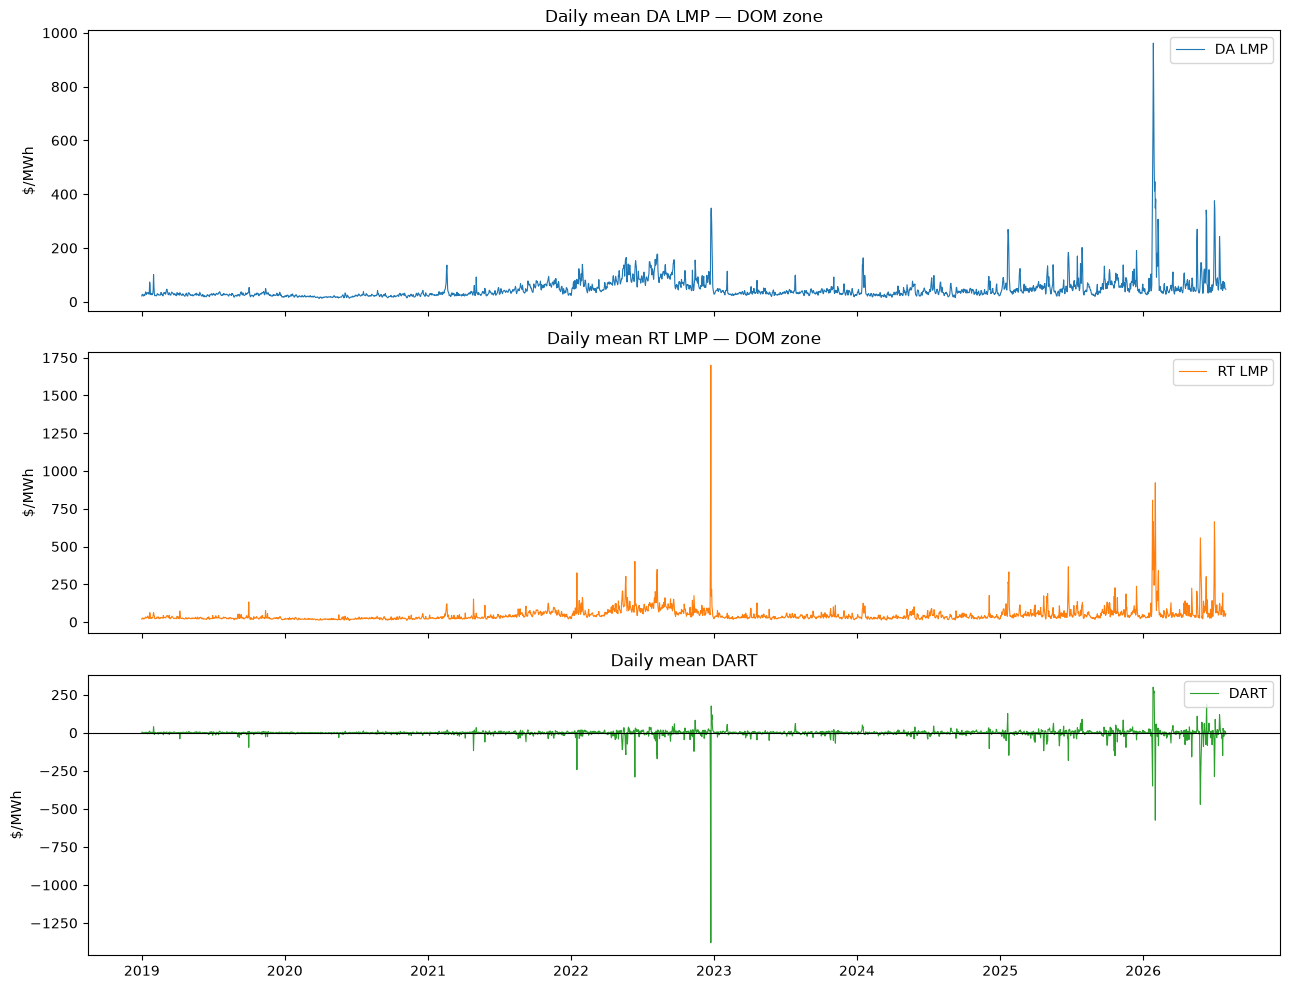

In [7]:
daily = df.resample("D").mean()

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].plot(daily.index, daily["da_lmp"], label="DA LMP", linewidth=0.8)
axes[0].set_ylabel("$/MWh")
axes[0].set_title("Daily mean DA LMP — DOM zone")
axes[0].legend()

axes[1].plot(daily.index, daily["rt_lmp"], label="RT LMP", linewidth=0.8, color="tab:orange")
axes[1].set_ylabel("$/MWh")
axes[1].set_title("Daily mean RT LMP — DOM zone")
axes[1].legend()

axes[2].plot(daily.index, daily["dart"],  label="DART", color="tab:green", linewidth=0.8)
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_ylabel("$/MWh")
axes[2].set_title("Daily mean DART")
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

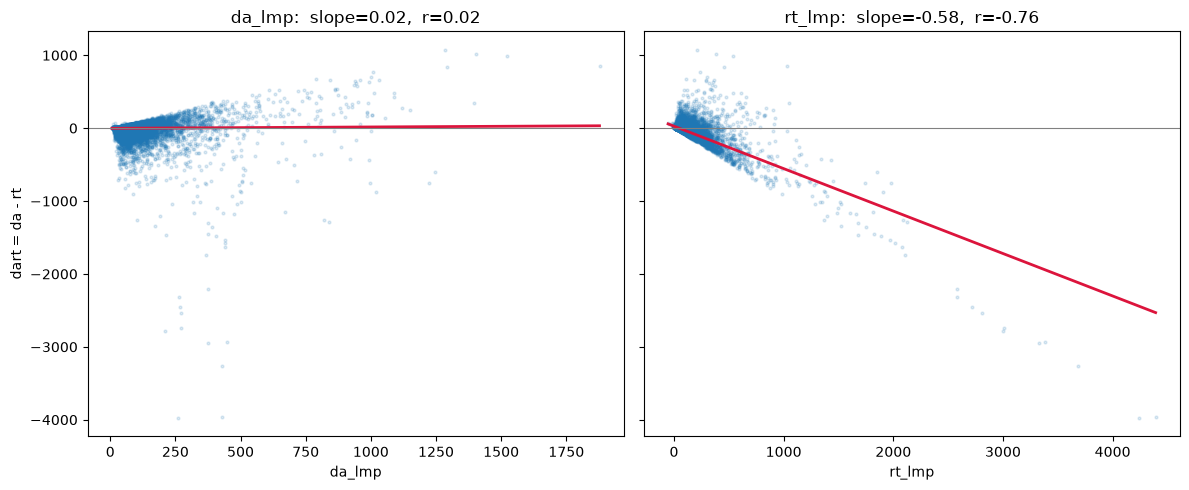

In [8]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, col in zip(axes, ["da_lmp", "rt_lmp"]):
    x, y = df[col], df["dart"]
    ax.scatter(x, y, s=4, alpha=0.15)
    
    b, a = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, a + b * xs, color="crimson", lw=2)

    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel(col)
    ax.set_title(f"{col}:  slope={b:.2f},  r={np.corrcoef(x, y)[0,1]:.2f}")

axes[0].set_ylabel("dart = da - rt")
plt.tight_layout()
plt.show()